<a href="https://colab.research.google.com/github/FrancoVenesia/TP_AA1_Perez_Venesia_Welsechen_CruzElizondoRios/blob/main/TP_clasificacion_AA1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# TP 2 Clasificación

### Integrantes:
- Welschen. Joaquín
- Venesia. Franco
- Elizondo Rios, Iñaki Cruz

Dataset: weatherAUS_2026C1.csv

# Consignas:
1. Realizar un análisis descriptivo, que ayude a la comprensión del problema, de cada
una de las variables involucradas, detallando: características, comportamiento y
rango de variación. ¿Qué es cada variable?
Debe incluir:
    -  Análisis y decisión sobre datos faltantes.
    -  Visualización de datos (por ejemplo histogramas, scatterplots entre variables,
    diagramas de caja)
    -  ¿Está balanceado el dataset? ¿Por qué cree que hacemos esta pregunta?
    -  Codificación de variables categóricas (si se van a utilizar para predicción).
    -  Matriz de correlación de variables.
    -  Estandarización/escalado de datos.
    -  Validación cruzada train - test. Realizar una división del conjunto de datos en conjuntos de entrenamiento y prueba (y si se quiere, se puede incluir
    validación, que luego será útil) en el MOMENTO donde lo crean adecuado.

2. Implementar la solución del problema de clasificación con regresión logística.
    - Obtener las métricas adecuadas (accuracy, precision, recall, F1 score, entre
    otras, ¡investiguen adicionales!). Graficar matrices de confusión para cada
    modelo. Analizar “falsos negativos” y “falsos positivos”, ¿qué significa cada
    uno?
    - Trazar curvas ROC para cada modelo. Comenten cuáles serían los umbrales
    adecuados a utilizar; ¿cómo podrían calcular el mejor umbral? ¿Es 0.5 el
    mejor?
    - ¿Creen que han conseguido un buen fitting?

## Librerias

In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Exploracion y limpieza de datos

### Carga y primera inspeccion

In [11]:
# LA SERIE DE TIEMPO CUIDADO AL DIVIDIR EN TRAIN TEST VAL, ORDENAR EL DATASET EN EJEMPLO 6, 2, 2 AÑOS
# SIN COS PARA VARIABLES CATEGORICAS
# ITEM 3 ES REPETIR EL ITEM 2

In [12]:
df = pd.read_csv('weatherAUS_2026C2.csv')

#Dimensiones del dataset
print(f'Filas: {df.shape[0]} | Columnas: {df.shape[1]}')


df.head(10)

Filas: 145412 | Columnas: 25


,Unnamed: 0,Date,Location,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustDir,WindGustSpeed,WindDir9am,WindDir3pm,WindSpeed9am,WindSpeed3pm,Humidity9am,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RainToday,RainTomorrow,RainfallTomorrow
0,0,2008-12-01,Albury,13.6,22.5,0.6,NaN,NaN,W,45.0,W,WNW,19.0,25.0,68.8,23.8,1008.1,1007.2,8.0,NaN,16.8,20.8,No,No,0.0
1,1,2008-12-02,Albury,7.3,25.8,0.0,NaN,NaN,WNW,44.0,NNW,WSW,4.0,23.0,40.1,22.1,1011.1,1007.5,NaN,NaN,18.3,24.6,No,No,0.0
2,2,2008-12-03,Albury,13.2,26.2,0.0,NaN,NaN,WSW,46.0,W,WSW,20.0,27.0,36.2,31.5,1007.3,1009.4,NaN,2.0,21.2,23.4,No,No,0.0
3,3,2008-12-04,Albury,10.0,28.8,0.0,NaN,NaN,NE,23.0,SE,E,10.0,10.0,45.8,18.5,1017.6,1012.4,NaN,NaN,17.4,26.3,No,No,1.0
4,4,2008-12-05,Albury,17.4,32.4,1.0,NaN,NaN,W,41.0,ENE,NW,6.0,17.0,83.5,34.6,1010.9,1005.9,7.0,8.0,17.9,29.1,No,No,0.2
5,5,2008-12-06,Albury,14.5,30.1,0.2,NaN,NaN,WNW,55.0,W,W,19.0,24.0,56.6,23.0,1009.9,1005.5,NaN,NaN,20.9,28.2,No,No,0.0
6,6,2008-12-07,Albury,15.1,25.3,0.0,NaN,NaN,W,51.0,SW,W,21.0,24.0,46.8,20.3,1009.3,1008.5,1.0,NaN,18.3,24.0,No,No,0.0
7,7,2008-12-08,Albury,8.1,26.1,0.0,NaN,NaN,W,34.0,SSE,W,5.0,16.0,46.8,20.8,1013.5,1009.7,NaN,NaN,17.1,25.9,No,No,0.0
8,8,2008-12-09,Albury,9.5,31.8,0.0,NaN,NaN,NNW,80.0,SE,NW,6.0,28.0,42.1,8.5,1008.9,1003.6,NaN,NaN,18.0,28.9,No,Yes,1.4
9,9,2008-12-10,Albury,13.4,30.1,1.4,NaN,NaN,W,28.0,S,SSE,14.0,12.0,57.6,24.6,1007.2,1005.7,NaN,NaN,18.9,28.2,Yes,No,0.0


In [13]:
#Informacion de tipos de datos y Cantidad de valores no nulos por columna
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 145412 entries, 0 to 145411
Data columns (total 25 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   Unnamed: 0        145412 non-null  int64  
 1   Date              145412 non-null  object 
 2   Location          145412 non-null  object 
 3   MinTemp           143928 non-null  float64
 4   MaxTemp           144159 non-null  float64
 5   Rainfall          142152 non-null  float64
 6   Evaporation       82658 non-null   float64
 7   Sunshine          75616 non-null   float64
 8   WindGustDir       135096 non-null  object 
 9   WindGustSpeed     135159 non-null  float64
 10  WindDir9am        134850 non-null  object 
 11  WindDir3pm        141186 non-null  object 
 12  WindSpeed9am      143645 non-null  float64
 13  WindSpeed3pm      142351 non-null  float64
 14  Humidity9am       142759 non-null  float64
 15  Humidity3pm       140907 non-null  float64
 16  Pressure9am       13

### Diccionario de variables

Cada fila es una observación diaria de una estación meteorológica. Las variables son:

| Variable | Descripción | Tipo | Unidad |
|---|---|---|---|
| `Unnamed: 0` | Índice de fila del archivo original. No aporta información. | entero | - |
| `Date` | Fecha de la observación. | fecha | - |
| `Location` | Ciudad / estación donde se tomó la observación (49 distintas). | categórica nominal | - |
| `MinTemp` | Temperatura mínima del día. | numérica continua | °C |
| `MaxTemp` | Temperatura máxima del día. | numérica continua | °C |
| `Rainfall` | Lluvia caída en las 24 h previas a las 9 am. | numérica continua | mm |
| `Evaporation` | Evaporación (tanque clase A) en las 24 h previas a las 9 am. | numérica continua | mm |
| `Sunshine` | Horas de sol del día. | numérica continua | horas |
| `WindGustDir` | Dirección de la ráfaga de viento más fuerte del día (16 puntos cardinales). | categórica nominal | - |
| `WindGustSpeed` | Velocidad de esa ráfaga máxima. | numérica continua | km/h |
| `WindDir9am`, `WindDir3pm` | Dirección del viento a las 9 am y a las 3 pm. | categórica nominal | - |
| `WindSpeed9am`, `WindSpeed3pm` | Velocidad media del viento en los 10 minutos previos a las 9 am / 3 pm. | numérica continua | km/h |
| `Humidity9am`, `Humidity3pm` | Humedad relativa a las 9 am / 3 pm. | numérica continua | % |
| `Pressure9am`, `Pressure3pm` | Presión atmosférica reducida al nivel del mar a las 9 am / 3 pm. | numérica continua | hPa |
| `Cloud9am`, `Cloud3pm` | Fracción del cielo cubierta por nubes a las 9 am / 3 pm. | numérica discreta (0 a 8) | octas |
| `Temp9am`, `Temp3pm` | Temperatura a las 9 am / 3 pm. | numérica continua | °C |
| `RainToday` | `Yes` si `Rainfall` supera 1 mm, `No` en otro caso. | categórica binaria | - |
| `RainTomorrow` | **Variable objetivo**: `Yes` si al día siguiente llovió más de 1 mm. | categórica binaria | - |
| `RainfallTomorrow` | Lluvia caída al día siguiente. | numérica continua | mm |

`RainfallTomorrow` es lo que queremos predecir: a las 23:59 no la conocemos y `RainTomorrow` se calcula directamente a partir de ella.

Si la dejamos, el modelo tendría información que no va a estar disponible al momento de predecir (fuga de datos), así que la eliminamos. El resto de las variables sí se conocen a las 23:59 del día.

También eliminamos `Unnamed: 0`, que es solamente un índice.


In [14]:
# Verificación del leakage entre RainfallTomorrow y RainTomorrow
# Comprobamos la relación entre ambas columnas
check = df.dropna(subset=['RainTomorrow', 'RainfallTomorrow']).copy()
check['rainfall_geq_1'] = (check['RainfallTomorrow'] >= 1).map({True: 'Yes', False: 'No'})

print("Tabla cruzada entre 'RainfallTomorrow >= 1' y 'RainTomorrow':")
print(pd.crosstab(check['rainfall_geq_1'], check['RainTomorrow']))

print("\n¿Coinciden en todos los casos?:",
      (check['rainfall_geq_1'] == check['RainTomorrow']).mean())

Tabla cruzada entre 'RainfallTomorrow >= 1' y 'RainTomorrow':
RainTomorrow        No    Yes
rainfall_geq_1               
No              108522      0
Yes               1759  31872

¿Coinciden en todos los casos?: 0.9876260085963715


In [15]:
# Eliminamos el índice y la variable con data leakage
df = df.drop(columns=['Unnamed: 0', 'RainfallTomorrow'])

Se elimina las filas que no contengan valor en la variable objetivo

In [16]:
# Filas sin variable objetivo: no sirven para entrenar ni para evaluar
print('Filas sin RainTomorrow:', df['RainTomorrow'].isna().sum(), f"({df['RainTomorrow'].isna().mean():.1%})")
df = df.dropna(subset=['RainTomorrow']).reset_index(drop=True)
print(df.shape)

Filas sin RainTomorrow: 3259 (2.2%)
(142153, 23)


In [17]:
# Pasamos la fecha a datetime y extraemos el mes, que usaremos para capturar la estacionalidad
df['Date'] = pd.to_datetime(df['Date'])
df['Month'] = df['Date'].dt.month
print(df['Date'].min(), '->', df['Date'].max())

2007-11-01 00:00:00 -> 2017-06-24 00:00:00


In [18]:
# Consistencia: duplicados y relación entre Rainfall y RainToday
print('Filas duplicadas:', df.duplicated().sum())
print('Fecha y ciudad repetidas:', df.duplicated(['Date', 'Location']).sum())
con_dato = df['Rainfall'].notna() & df['RainToday'].notna()
print('RainToday coincide con Rainfall > 1 mm:', ((df['Rainfall'] > 1) == (df['RainToday'] == 'Yes'))[con_dato].mean())
print('Días con MinTemp > MaxTemp:', (df['MinTemp'] > df['MaxTemp']).sum())

Filas duplicadas: 0
Fecha y ciudad repetidas: 0
RainToday coincide con Rainfall > 1 mm: 1.0
Días con MinTemp > MaxTemp: 68


No hay filas duplicadas y `RainToday` es siempre consistente con `Rainfall` (vale `Yes` exactamente cuando llovió más de 1 mm). Esto nos sirve más adelante para completar `RainToday` cuando falta.

Hay unos pocos días donde la mínima supera a la máxima. Las diferencias son de décimas de grado y se explican porque la mínima y la máxima se registran en ventanas de 24 h distintas, así que no las consideramos errores y las dejamos.

### 1.4 División en train y test

Se realiza la division previo de analisis detallado, imputacion o escalamiento.

Todo lo que se calcula a partir de los datos (medianas para imputar, medias y desvíos para escalar, umbrales de decisión) se obtiene sólo de train, y validación y test se transforman con esos valores.

Al componerse los datos de una serie temporal, la division debe realizarse respecto a un corte en el tiempo. Si mezcláramos al azar, quedarían en train días inmediatamente anteriores y posteriores a los de test, que son muy similares. Por eso dividimos por fecha:

- **train**: hasta el 31/12/2015
- **test**: desde el 01/01/2016 (sólo para la evaluación final)

In [19]:
# División temporal del dataset
train = df[df['Date'] < '2016-01-01'].copy()
test = df[df['Date'] >= '2016-01-01'].copy()

pd.DataFrame({
    'filas': [len(x) for x in (train, test)],
    '% del total': [round(len(x) / len(df) * 100, 1) for x in (train, test)],
    'desde': [x['Date'].min().date() for x in (train, test)],
    'hasta': [x['Date'].max().date() for x in (train, test)],
    '% RainTomorrow = Yes': [round((x['RainTomorrow'] == 'Yes').mean() * 100, 1) for x in (train, test)],
}, index=['train', 'test'])

,filas,% del total,desde,hasta,% RainTomorrow = Yes
train,116219,81.8,2007-11-01,2015-12-31,22.3
test,25934,18.2,2016-01-01,2017-06-24,22.9


In [20]:
df = df.sort_values(by='Date').reset_index(drop=True)
print("Rango de fechas después de ordenar:", df['Date'].min(), "a", df['Date'].max())
df.head()

Rango de fechas después de ordenar: 2007-11-01 00:00:00 a 2017-06-24 00:00:00


,Date,Location,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustDir,WindGustSpeed,WindDir9am,WindDir3pm,WindSpeed9am,WindSpeed3pm,Humidity9am,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RainToday,RainTomorrow,Month
0,2007-11-01,Canberra,7.9,24.3,0.0,3.4,6.3,NW,29.0,SW,NW,7.0,20.0,63.9,28.1,1020.3,1014.7,7.0,7.0,14.4,23.5,No,Yes,11
1,2007-11-02,Canberra,13.3,27.0,3.6,4.4,9.7,ENE,38.0,E,W,5.0,14.0,79.4,35.8,1012.1,1008.5,5.0,3.0,17.4,25.6,Yes,Yes,11
2,2007-11-03,Canberra,13.9,23.1,3.6,5.8,3.3,NW,84.0,N,NNE,5.0,6.0,80.9,68.8,1009.6,1007.4,8.0,7.0,15.3,20.0,Yes,Yes,11
3,2007-11-04,Canberra,13.0,15.8,39.8,7.2,9.1,NW,54.0,WNW,W,30.0,23.0,62.7,55.9,1005.4,1007.0,2.0,7.0,13.1,13.3,Yes,Yes,11
4,2007-11-05,Canberra,7.8,16.4,2.8,5.6,10.6,SSE,49.0,SSE,ESE,19.0,28.0,67.5,50.1,1018.4,1018.6,7.0,7.0,11.4,15.9,Yes,No,11


In [ ]:
import numpy as np

# Suponiendo que 'X' son tus características e 'y' tu variable objetivo
# Generamos datos de ejemplo (100 filas)


# 1. Definir los puntos de corte cronológicos
total_len = len(X)
train_end = int(total_len * 0.70)          # Fin del 70%
val_end = int(total_len * (0.70 + 0.15))   # Fin del 85% (70% + 15%)

# 2. Dividir los datos respetando el orden del tiempo
X_train, y_train = X[:train_end], y[:train_end]
X_val, y_val     = X[train_end:val_end], y[train_end:val_end]
X_test, y_test   = X[val_end:], y[val_end:]

# Verificar los tamaños
print(f"Entrenamiento: {len(X_train)} muestras ({len(X_train)/total_len:.2%})")
print(f"Validación:    {len(X_val)} muestras ({len(X_val)/total_len:.2%})")
print(f"Prueba:        {len(X_test)} muestras ({len(X_test)/total_len:.2%})")


In [27]:
# Definir los tamaños de las particiones
total_len = len(df)
train_end = int(total_len * 0.70)
val_end = int(total_len * (0.70 + 0.15))

# Dividir de forma secuencial respetando la serie de tiempo
train_df = df.iloc[:train_end].copy()
val_df   = df.iloc[train_end:val_end].copy()
test_df  = df.iloc[val_end:].copy()

# # Verificar rangos de fechas y dimensiones
# for name, dataset in [('Train', train_df), ('Validation', val_df), ('Test', test_df)]:
#     print(f"{name}: {len(dataset)} muestras ({len(dataset)/total_len:.2%}) | "
#           f"Desde {dataset['Date'].min().date()} hasta {dataset['Date'].max().date()}")
train_df.tail()


,Date,Location,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustDir,WindGustSpeed,WindDir9am,WindDir3pm,WindSpeed9am,WindSpeed3pm,Humidity9am,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RainToday,RainTomorrow,Month
99502,2015-01-12,Wollongong,18.9,23.1,21.6,NaN,NaN,SSW,54.0,SSW,S,39.0,40.0,90.2,79.3,1016.5,1014.5,8.0,8.0,20.3,21.1,Yes,Yes,1
99503,2015-01-12,BadgerysCreek,18.8,25.4,13.8,NaN,NaN,SSE,40.0,S,SSE,13.0,18.0,88.2,68.8,1016.0,1013.5,NaN,NaN,20.2,24.4,Yes,No,1
99504,2015-01-12,Perth,15.3,35.9,0.0,12.0,13.2,SW,38.0,ENE,SW,11.0,22.0,26.4,21.1,1008.2,1006.0,0.0,0.0,27.1,31.9,No,No,1
99505,2015-01-12,SalmonGums,6.7,31.3,0.0,NaN,NaN,SE,47.0,NE,SSE,5.0,11.0,42.8,18.2,NaN,NaN,NaN,NaN,20.8,30.3,No,No,1
99506,2015-01-12,MountGambier,14.2,34.6,0.0,4.0,10.3,NE,45.0,E,ENE,13.0,18.0,59.2,30.8,1012.0,1006.8,1.0,6.0,21.6,32.8,No,Yes,1


In [25]:
val_df.head()

,Date,Location,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustDir,WindGustSpeed,WindDir9am,WindDir3pm,WindSpeed9am,WindSpeed3pm,Humidity9am,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RainToday,RainTomorrow,Month
99507,2015-01-12,Mildura,19.3,28.7,0.0,1.6,1.7,NE,34.0,E,ENE,16.0,18.0,77.8,69.9,1009.5,1007.5,7.0,8.0,24.1,26.3,No,Yes,1
99508,2015-01-12,Tuggeranong,15.7,23.0,2.6,NaN,NaN,ENE,36.0,ESE,ENE,19.0,20.0,60.8,51.3,1015.4,1012.7,NaN,NaN,17.9,22.3,Yes,No,1
99509,2015-01-12,Dartmoor,14.6,35.0,0.0,4.0,10.3,ESE,44.0,E,ESE,12.0,17.0,81.0,36.7,1013.2,1007.7,NaN,NaN,19.3,32.5,No,Yes,1
99510,2015-01-12,Albany,16.1,23.1,0.0,7.4,12.9,NaN,NaN,E,SE,19.0,29.0,58.5,66.1,1011.5,1009.6,1.0,1.0,21.8,21.4,No,No,1
99511,2015-01-12,Nhil,17.7,33.7,0.0,NaN,NaN,ENE,47.0,ENE,ENE,26.0,25.0,65.6,40.3,1011.6,1006.4,NaN,NaN,22.9,30.7,No,Yes,1


In [26]:
test_df.head()

,Date,Location,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustDir,WindGustSpeed,WindDir9am,WindDir3pm,WindSpeed9am,WindSpeed3pm,Humidity9am,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RainToday,RainTomorrow,Month
120830,2016-04-07,WaggaWagga,6.6,23.3,0.0,8.0,10.5,WSW,24.0,NNW,WSW,2.0,11.0,72.0,19.6,1023.3,1019.9,2.0,7.0,13.7,22.4,No,No,4
120831,2016-04-07,Richmond,16.6,20.8,0.0,5.4,NaN,SE,34.0,SE,ESE,20.0,17.0,64.2,54.4,1023.6,1022.9,8.0,8.0,20.3,21.3,No,No,4
120832,2016-04-07,Walpole,8.9,19.4,0.0,NaN,NaN,SSE,25.0,NaN,SSE,0.0,12.0,83.5,63.5,1027.7,1024.8,NaN,NaN,15.0,19.5,No,No,4
120833,2016-04-07,MelbourneAirport,7.4,18.9,3.4,2.0,6.2,S,34.0,WSW,S,7.0,18.0,67.7,57.2,1025.5,1023.4,1.0,7.0,14.0,17.4,Yes,No,4
120834,2016-04-07,Penrith,19.7,21.0,0.0,NaN,NaN,SE,25.0,SE,E,14.0,7.0,66.3,55.1,NaN,NaN,NaN,NaN,18.9,20.9,No,No,4


In [ ]:
#Estadisticas variables numericas

df.describe()

,Unnamed: 0,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustSpeed,WindSpeed9am,WindSpeed3pm,Humidity9am,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RainfallTomorrow
count,124792.000000,123437.000000,123635.000000,121827.000000,71884.00000,66728.000000,114866.000000,123104.000000,121814.000000,122317.000000,121217.000000,112924.000000,112960.000000,79009.000000,76174.000000,123117.000000,121955.000000,121828.000000
mean,62414.785371,11.999173,22.889544,2.371955,5.33460,7.543497,39.947487,14.066562,18.794301,69.735285,52.253079,1018.026505,1015.699630,4.511043,4.551711,16.712059,21.404468,2.371639
std,36036.244549,6.211467,6.896954,8.462480,4.20635,3.809995,13.767944,9.089367,9.089137,18.413891,20.490605,6.987979,6.871572,2.881618,2.715758,6.253785,6.716102,8.462170
min,0.000000,-9.700000,-5.100000,0.000000,0.00000,0.000000,6.000000,0.000000,0.000000,0.000000,0.000000,980.300000,980.000000,0.000000,0.000000,-8.000000,-5.800000,0.000000
25%,31206.750000,7.600000,17.900000,0.000000,2.60000,4.700000,30.000000,7.000000,12.000000,57.700000,37.600000,1013.400000,1011.100000,1.000000,2.000000,12.200000,16.600000,0.000000
50%,62414.500000,11.900000,22.500000,0.000000,4.40000,8.300000,38.000000,13.000000,18.000000,70.400000,52.500000,1018.000000,1015.700000,5.000000,5.000000,16.600000,21.000000,0.000000
75%,93623.250000,16.600000,27.600000,0.800000,7.20000,10.600000,48.000000,19.000000,24.000000,83.700000,66.100000,1022.700000,1020.300000,7.000000,7.000000,21.200000,25.900000,0.800000
max,124831.000000,34.100000,49.100000,371.000000,145.00000,14.500000,135.000000,130.000000,86.000000,100.000000,100.000000,1041.200000,1038.300000,9.000000,9.000000,39.800000,47.000000,371.000000


In [ ]:
#Estadisticas variables categóricas

df.describe(include='object')

,Date,Location,WindGustDir,WindDir9am,WindDir3pm,RainToday,RainTomorrow
count,145412,145412,135096,134850,141186,142152,142153
unique,3435,49,16,16,16,2,2
top,2017-06-24,Canberra,W,N,SE,No,No
freq,49,3435,9910,11754,10837,110276,110281


In [ ]:
# Resumen consolidado: tipo, nulos, % nulos, valores únicos
resumen = pd.DataFrame({
    'Tipo': df.dtypes,
    'No_Nulos': df.notnull().sum(),
    'Nulos': df.isnull().sum(),
    '%_Nulos': (df.isnull().sum() / len(df) * 100).round(2),
    'Valores_Unicos': df.nunique()
})
resumen.sort_values('%_Nulos', ascending=False)

,Tipo,No_Nulos,Nulos,%_Nulos,Valores_Unicos
Sunshine,float64,75616,69796,48.00,145
Evaporation,float64,82658,62754,43.16,358
Cloud3pm,float64,86076,59336,40.81,10
Cloud9am,float64,89542,55870,38.42,10
Pressure9am,float64,130351,15061,10.36,547
Pressure3pm,float64,130388,15024,10.33,542
WindDir9am,object,134850,10562,7.26,16
WindGustDir,object,135096,10316,7.09,16
WindGustSpeed,float64,135159,10253,7.05,120
Humidity3pm,float64,140907,4505,3.10,995


In [ ]:
# Descartamos columnas que no aportan o que generan leakage
df = df.drop(columns=['Unnamed: 0', 'RainfallTomorrow'])
print(f'Columnas restantes: {df.shape[1]}')
df.head()

Columnas restantes: 23


,Date,Location,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustDir,WindGustSpeed,WindDir9am,...,Humidity9am,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RainToday,RainTomorrow
0,2008-12-01,Albury,13.6,22.5,0.6,NaN,NaN,W,45.0,W,...,68.8,23.8,1008.1,1007.2,8.0,NaN,16.8,20.8,No,No
1,2008-12-02,Albury,7.3,25.8,0.0,NaN,NaN,WNW,44.0,NNW,...,40.1,22.1,1011.1,1007.5,NaN,NaN,18.3,24.6,No,No
2,2008-12-03,Albury,13.2,26.2,0.0,NaN,NaN,WSW,46.0,W,...,36.2,31.5,1007.3,1009.4,NaN,2.0,21.2,23.4,No,No
3,2008-12-04,Albury,10.0,28.8,0.0,NaN,NaN,NE,23.0,SE,...,45.8,18.5,1017.6,1012.4,NaN,NaN,17.4,26.3,No,No
4,2008-12-05,Albury,17.4,32.4,1.0,NaN,NaN,W,41.0,ENE,...,83.5,34.6,1010.9,1005.9,7.0,8.0,17.9,29.1,No,No


In [ ]:
# Se borran las filas con la variable target vacía
df = df.dropna(subset=['RainTomorrow'])

print((df['RainTomorrow'].value_counts(dropna=False)))

RainTomorrow
No     110281
Yes     31872
Name: count, dtype: int64


In [ ]:
# Se reemplaza por valores binarios
df['RainTomorrow'] = df['RainTomorrow'].astype(str).str.strip().str.title().replace({'Yes': 1, 'No': 0})
df['RainToday'] = df['RainToday'].astype(str).str.strip().str.title().replace({'Yes': 1, 'No': 0})

# Verificamos
print('RainTomorrow:')
print(df['RainTomorrow'].value_counts(dropna=False))
print('\nRainToday:')
print(df['RainToday'].value_counts(dropna=False))

RainTomorrow:
RainTomorrow
0    110281
1     31872
Name: count, dtype: int64

RainToday:
RainToday
0      109296
1       31451
Nan      1406
Name: count, dtype: int64


/tmp/ipykernel_1344/79365261.py:2: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df['RainTomorrow'] = df['RainTomorrow'].astype(str).str.strip().str.title().replace({'Yes': 1, 'No': 0})


In [ ]:
# Convertimos Date a tipo datetime
df['Date'] = pd.to_datetime(df['Date'])

# Verificamos rango temporal
print(f'Fecha mínima: {df["Date"].min().date()}')
print(f'Fecha máxima: {df["Date"].max().date()}')
print(f'Años cubiertos: {df["Date"].dt.year.nunique()}')

Fecha mínima: 2007-11-01
Fecha máxima: 2017-06-24
Años cubiertos: 11


In [ ]:
# Extraemos el día del año (1-365/366)
df['DayOfYear'] = df['Date'].dt.dayofyear

# Creación columna que almacena el mes de cada fecha
df['Month'] = df['Date'].dt.month

# Codificación cíclica: mapea el día del año a un punto del círculo unitario
df['DayOfYear_sin'] = np.sin(2 * np.pi * df['DayOfYear'] / 365)
df['DayOfYear_cos'] = np.cos(2 * np.pi * df['DayOfYear'] / 365)

# Codificación cíclica del mes
df['Month_sin'] = np.sin(2 * np.pi * df['Month'] / 12)
df['Month_cos'] = np.cos(2 * np.pi * df['Month'] / 12)

# Eliminamos las columnas auxiliares: Date original ya no la necesitamos,
# y DayOfYear queda reemplazada por sus componentes cíclicas
#df = df.drop(columns=['Date', 'DayOfYear'])

df.tail()

,Date,Location,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustDir,WindGustSpeed,WindDir9am,...,Temp9am,Temp3pm,RainToday,RainTomorrow,DayOfYear,Month,DayOfYear_sin,DayOfYear_cos,Month_sin,Month_cos
145407,2017-06-20,Uluru,2.6,22.0,0.0,NaN,NaN,E,29.0,ESE,...,10.1,21.6,0,0,171,6,0.196673,-0.980469,1.224647e-16,-1.0
145408,2017-06-21,Uluru,3.1,23.2,0.0,NaN,NaN,E,31.0,SE,...,11.1,21.5,0,0,172,6,0.179767,-0.983709,1.224647e-16,-1.0
145409,2017-06-22,Uluru,3.6,26.0,0.0,NaN,NaN,NNW,21.0,SE,...,11.8,24.5,0,0,173,6,0.162807,-0.986658,1.224647e-16,-1.0
145410,2017-06-23,Uluru,4.8,27.4,0.0,NaN,NaN,N,39.0,SE,...,12.0,26.9,0,0,174,6,0.145799,-0.989314,1.224647e-16,-1.0
145411,2017-06-24,Uluru,7.5,26.5,0.0,NaN,NaN,SE,28.0,SSE,...,14.7,26.8,0,0,175,6,0.128748,-0.991677,1.224647e-16,-1.0


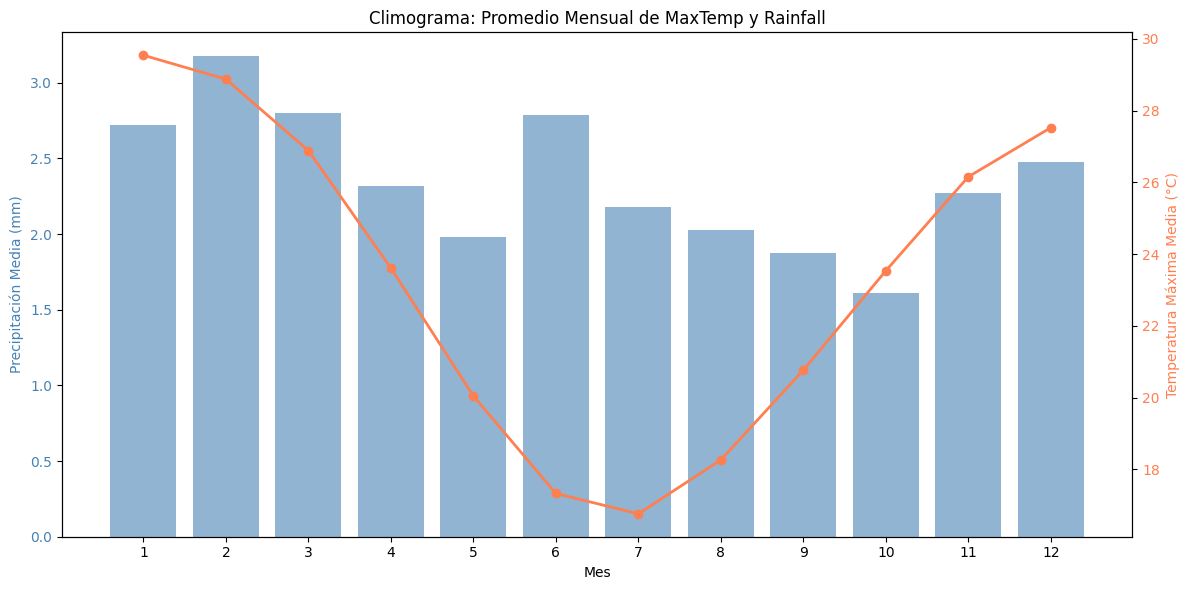

In [ ]:
# Se calcula las medias mensuales
monthly_data = df.groupby('Month').agg({'MaxTemp': 'mean', 'Rainfall': 'mean'}).reset_index()

fig, ax1 = plt.subplots(figsize=(12, 6))

# Eje primario para la Precipitación
color_rain = 'steelblue'
ax1.set_xlabel('Mes')
ax1.set_ylabel('Precipitación Media (mm)', color=color_rain)
ax1.bar(monthly_data['Month'], monthly_data['Rainfall'], color=color_rain, alpha=0.6, label='Rainfall')
ax1.tick_params(axis='y', labelcolor=color_rain)
ax1.set_xticks(range(1, 13))

# Eje secundario para la Temperatura
ax2 = ax1.twinx()
color_temp = 'coral'
ax2.set_ylabel('Temperatura Máxima Media (°C)', color=color_temp)
ax2.plot(monthly_data['Month'], monthly_data['MaxTemp'], color=color_temp, marker='o', linewidth=2, label='MaxTemp')
ax2.tick_params(axis='y', labelcolor=color_temp)

plt.title('Climograma: Promedio Mensual de MaxTemp y Rainfall')
fig.tight_layout()
plt.show()

# Mas util separado por region

In [ ]:
# Coordenadas (latitud, longitud) de las 33 ciudades del dataset
coordenadas_ciudades = {
    'Albury':          (-36.0737, 146.9135),
    'BadgerysCreek':   (-33.8830, 150.7717),
    'Cobar':           (-31.4980, 145.8347),
    'CoffsHarbour':    (-30.2963, 153.1135),
    'Moree':           (-29.4640, 149.8344),
    'Newcastle':       (-32.9283, 151.7817),
    'NorahHead':       (-33.2833, 151.5667),
    'NorfolkIsland':   (-29.0408, 167.9547),
    'Penrith':         (-33.7510, 150.6940),
    'Richmond':        (-33.5996, 150.7510),
    'Sydney':          (-33.8688, 151.2093),
    'SydneyAirport':   (-33.9399, 151.1753),
    'WaggaWagga':      (-35.1082, 147.3598),
    'Williamtown':     (-32.8150, 151.8428),
    'Wollongong':      (-34.4278, 150.8931),
    'Canberra':        (-35.2809, 149.1300),
    'Tuggeranong':     (-35.4156, 149.0888),
    'MountGinini':     (-35.5294, 148.7723),
    'Ballarat':        (-37.5622, 143.8503),
    'Bendigo':         (-36.7570, 144.2794),
    'Sale':            (-38.1051, 147.0658),
    'MelbourneAirport':(-37.6733, 144.8433),
    'Melbourne':       (-37.8136, 144.9631),
    'Mildura':         (-34.2080, 142.1246),
    'Nhil':            (-36.3328, 141.6503),
    'Portland':        (-38.3457, 141.6042),
    'Watsonia':        (-37.7110, 145.0830),
    'Dartmoor':        (-37.9220, 141.2760),
    'Brisbane':        (-27.4698, 153.0251),
    'Cairns':          (-16.9186, 145.7781),
    'GoldCoast':       (-28.0167, 153.4000),
    'Townsville':      (-19.2589, 146.8169),
    'Adelaide':        (-34.9285, 138.6007),
}

# Verificamos que están todas las ciudades del dataset
ciudades_dataset = set(df['Location'].unique())
ciudades_dict = set(coordenadas_ciudades.keys())

print(f'Ciudades en dataset: {len(ciudades_dataset)}')
print(f'Ciudades en diccionario: {len(ciudades_dict)}')
print(f'Faltantes en el diccionario: {ciudades_dataset - ciudades_dict}')
print(f'Sobran en el diccionario: {ciudades_dict - ciudades_dataset}')

Ciudades en dataset: 49
Ciudades en diccionario: 33
Faltantes en el diccionario: {'Albany', 'Katherine', 'Woomera', 'Launceston', 'AliceSprings', 'Uluru', 'Nuriootpa', 'Darwin', 'PerthAirport', 'Hobart', 'Perth', 'SalmonGums', 'PearceRAAF', 'MountGambier', 'Walpole', 'Witchcliffe'}
Sobran en el diccionario: set()


In [ ]:
ciudades_faltantes = ['PerthAirport', 'SalmonGums', 'Nuriootpa', 'Woomera', 'Albany', 'AliceSprings',
                      'Katherine', 'PearceRAAF', 'Uluru', 'Darwin', 'Launceston',
                      'Hobart', 'Witchcliffe', 'Walpole', 'MountGambier', 'Perth']

print("Cantidad de filas sin Region",len(df[df['Location'].isin(ciudades_faltantes)]))

Cantidad de filas sin Region 45238
